### Final Inference Eval

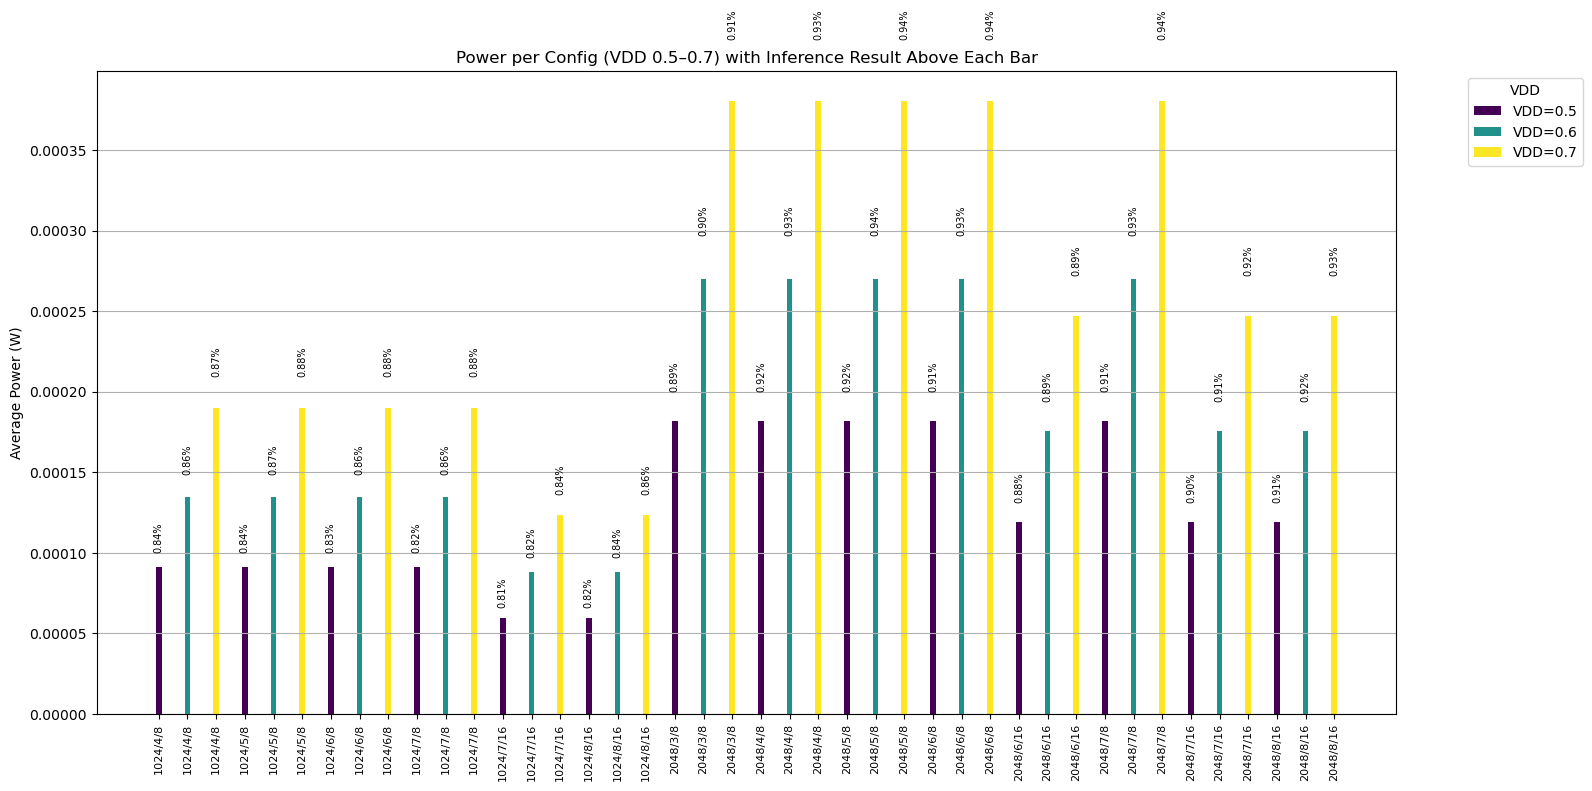

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# Load the data
data = np.load('conf_matrix_results/inference_results.npy', allow_pickle=True)

# Filter only allowed VDDs
allowed_vdds = [0.5, 0.6, 0.7]

# Grouping
grouped = defaultdict(list)
for entry in data:
    if entry['vdd'] not in allowed_vdds:
        continue
    config_key = (
        entry['vec_dim'],
        entry['precision'],
        entry['block_size'],
        entry['inference_result']
    )
    grouped[config_key].append((entry['vdd'], entry['avg_power_vec']))

# Plotting
all_vdds = sorted(allowed_vdds)
fig, ax = plt.subplots(figsize=(16, 8))
bar_width = 0.2
colors = plt.cm.viridis(np.linspace(0, 1, len(all_vdds)))

x_ticks = []
tick_positions = []
bar_counter = 0

# Track which VDDs have already been added to the legend
vdd_plotted = set()

for i, (config, entries) in enumerate(sorted(grouped.items())):
    vec_dim, precision, block_size, inference_result = config
    vdd_to_power = dict(entries)

    for j, vdd in enumerate(all_vdds):
        power = vdd_to_power.get(vdd, None)
        if power is not None:
            x_pos = bar_counter

            # Add label only once per VDD
            label = f"VDD={vdd}" if vdd not in vdd_plotted else None
            ax.bar(x_pos, power, width=bar_width, color=colors[j], label=label)
            vdd_plotted.add(vdd)

            # Inference result above bar
            label_y = power * 1.10
            ax.text(x_pos, label_y, f"{inference_result:.2f}%", ha='center', va='bottom', fontsize=7, rotation=90)

            bar_counter += 1
            tick_positions.append(x_pos)
            x_ticks.append(f"{vec_dim}/{precision}/{block_size}")

# Final touches
ax.set_xticks(tick_positions)
ax.set_xticklabels(x_ticks, rotation=90, fontsize=8)
ax.set_ylabel("Average Power (W)")
ax.set_title("Power per Config (VDD 0.5–0.7) with Inference Result Above Each Bar")
ax.legend(title="VDD", bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, axis='y')

plt.tight_layout()
plt.show()
